17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Samples: 25000
Testing Samples: 25000
Training Data Shape: (25000, 200)
Testing Data Shape: (25000, 200)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 58s 177ms/step - accuracy: 0.5426 - loss: 0.6860 - val_accuracy: 0.5722 - val_loss: 0.6649
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 53s 171ms/step - accuracy: 0.7110 - loss: 0.5348 - val_accuracy: 0.8372 - val_loss: 0.3807
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 52s 166ms/step - accuracy: 0.8920 - loss: 0.2724 - val_accuracy: 0.8922 - val_loss: 0.2774
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 52s 165ms/step - accuracy: 0.9395 - loss: 0.1720 - val_accuracy: 0.8856 - val_loss: 0.2920
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 165ms/step - accuracy: 0.9627 - loss: 0.1164 - val_accuracy: 0.8804 - val_loss: 0.3225
782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - accuracy: 0.8681 - loss: 0.3423
Test Loss: 0.34232020378112793
Test Accuracy: 0.8680800199508667


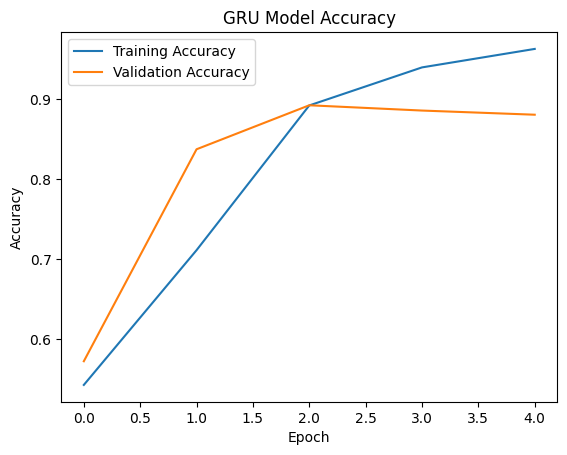

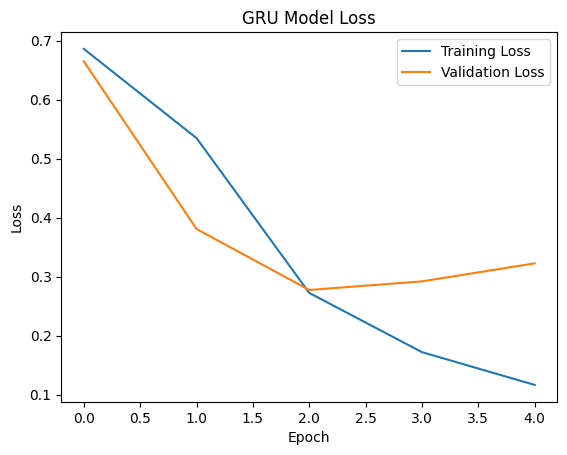

RNN with GRU completed successfully.
Test Accuracy: 86.81 %


In [1]:
# Experiment No. 9
# Sentiment Analysis using RNN with GRU

# 1. Import required libraries
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 2. Set parameters
vocab_size = 10000
max_length = 200

# 3. Load IMDB dataset
(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training Samples:", len(x_train))
print("Testing Samples:", len(x_test))

# 4. Pad sequences
x_train = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post'
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post'
)

print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

# 5. Build GRU model
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64
    ),
    GRU(64),
    Dense(1, activation='sigmoid')
])

# 6. Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 7. Display model architecture
model.summary()

# 8. Train model
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

# 9. Evaluate model
loss, accuracy = model.evaluate(
    x_test,
    y_test
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# 10. Plot training and validation accuracy
plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('GRU Model Accuracy')
plt.legend()
plt.show()

# 11. Plot training and validation loss
plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('GRU Model Loss')
plt.legend()
plt.show()

# 12. Result
print("RNN with GRU completed successfully.")
print("Test Accuracy:", round(accuracy * 100, 2), "%")